<a href="https://colab.research.google.com/github/marimorenom2007-create/mi-dashboard-ventas-final/blob/main/Taller_Gr%C3%A1ficos_Publicaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import glob
import pandas as pd

archivos = glob.glob("*.csv")
print("Archivos encontrados:", archivos)

df = pd.read_csv(archivos[0])
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month

print("Filas y columnas:", df.shape)
df.head()

Archivos encontrados: ['ventas_papelerias_2025.csv']
Filas y columnas: (2000, 14)


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


producto
Cuaderno          20712345
Block de notas    14292347
Resma carta       13133570
Marcador          10020786
Colores x12        9419625
Name: total, dtype: int64


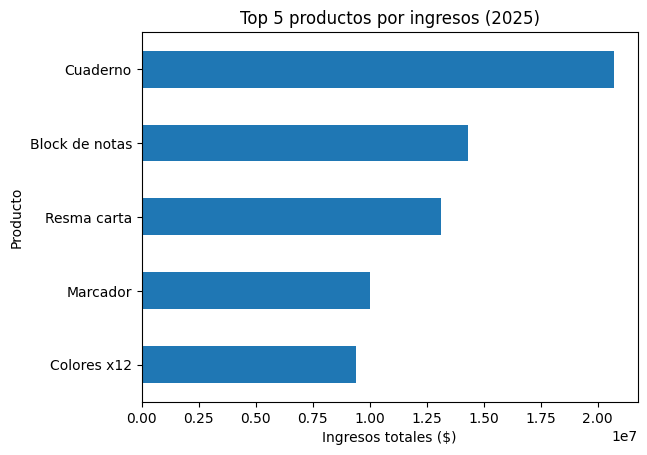

In [ ]:
top_productos = (
    df.groupby("producto")["total"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

ax = top_productos.sort_values().plot.barh(
    title="Top 5 productos por ingresos (2025)",
    xlabel="Ingresos totales ($)",
    ylabel="Producto"
)
print(top_productos)

Forma de la tabla: (12, 2)


ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


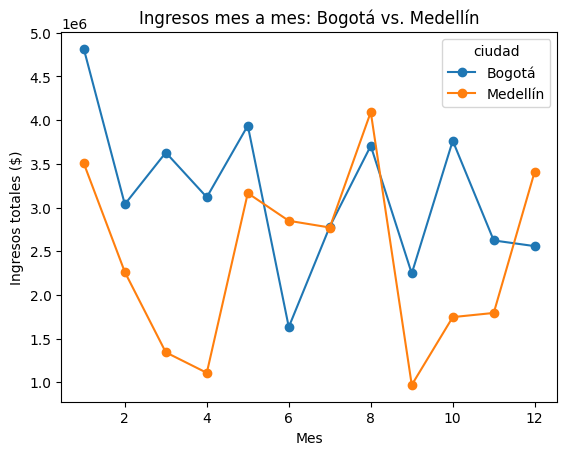

In [ ]:
ing_mes_ciudad = (
    df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
)

ax = ing_mes_ciudad.plot.line(
    marker="o",
    title="Ingresos mes a mes: Bogotá vs. Medellín",
    xlabel="Mes",
    ylabel="Ingresos totales ($)"
)
print("Forma de la tabla:", ing_mes_ciudad.shape)
ing_mes_ciudad

canal
Online        22887574
Telefónico    61450716
Tienda        34329722
Name: total, dtype: int64


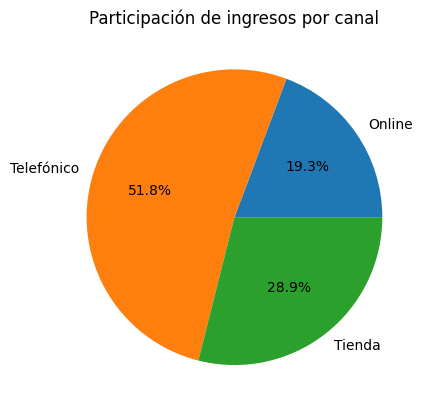

In [ ]:
ing_canal = df.groupby("canal")["total"].sum()

ax = ing_canal.plot.pie(
    autopct="%1.1f%%",
    title="Participación de ingresos por canal",
    ylabel=""
)
print(ing_canal)

categoria     Arte  Corrección  Escritura  Organización  Papel
segmento                                                      
Corporativo   2.81        5.40      30.24         23.33  38.23
Mayorista     5.62       12.22      54.03          5.62  22.49
Minorista    12.06       12.77      55.76          4.26  15.16


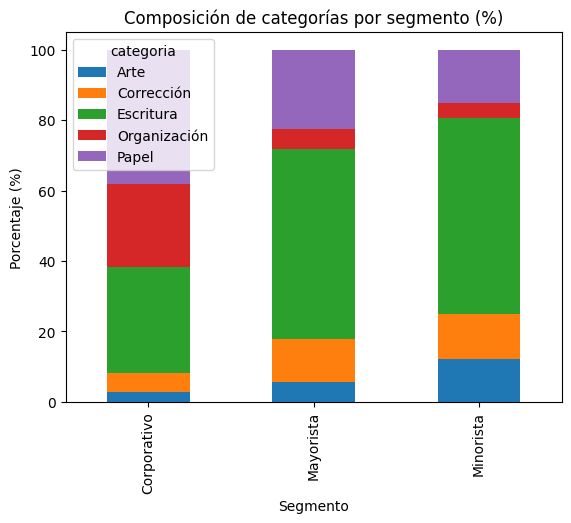

In [ ]:
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100

ax = tabla_seg_cat.plot.bar(
    stacked=True,
    title="Composición de categorías por segmento (%)",
    xlabel="Segmento",
    ylabel="Porcentaje (%)",
)
print(tabla_seg_cat.round(2))

Filas (vendedores): 12
Suma de n_ventas: 2000


,vendedor,ciudad,n_ventas,ticket_prom
0,Andrés Rojas,Medellín,192,60729.104167
1,Camilo Pardo,Bogotá,210,54276.595238
2,Daniela Ríos,Bogotá,130,62903.423077
3,Esteban Uribe,Medellín,94,61833.978723
4,Isabela Mora,Bucaramanga,108,65873.037037
5,Julián Cortés,Cali,215,56389.920930
6,Laura Gómez,Bogotá,312,58564.371795
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
9,Santiago Duarte,Bucaramanga,101,59798.841584


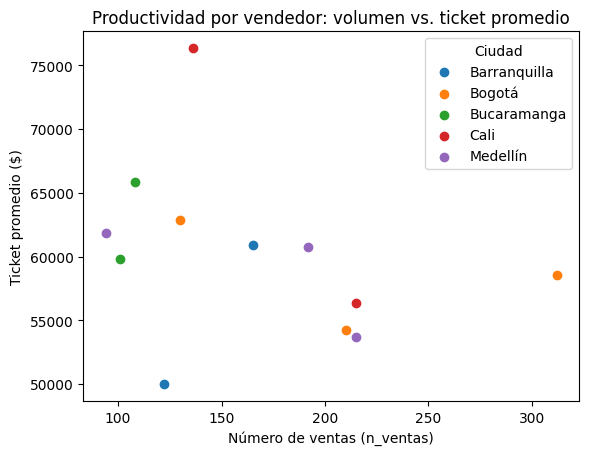

In [ ]:
import matplotlib.pyplot as plt

vend = (
    df.groupby(["vendedor", "ciudad"])
    .agg(n_ventas=("total", "count"), ticket_prom=("total", "mean"))
    .reset_index()
)

fig_ej5, ax_ej5 = plt.subplots()
for ciudad, grupo in vend.groupby("ciudad"):
    ax_ej5.scatter(
        grupo["n_ventas"],
        grupo["ticket_prom"],
        label=ciudad,
    )

ax_ej5.set_title("Productividad por vendedor: volumen vs. ticket promedio")
ax_ej5.set_xlabel("Número de ventas (n_ventas)")
ax_ej5.set_ylabel("Ticket promedio ($)")
ax_ej5.legend(title="Ciudad")

print("Filas (vendedores):", len(vend))
print("Suma de n_ventas:", vend["n_ventas"].sum())
vend

Ventas en el segundo semestre: 1050


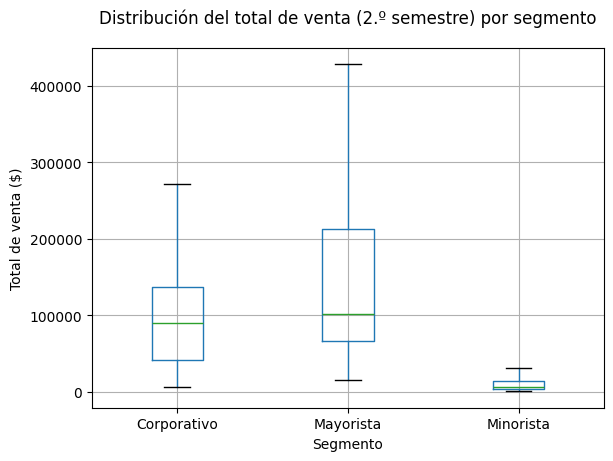

In [ ]:
import matplotlib.pyplot as plt

sem2 = df[df["mes"] >= 7]

ax = sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False,
)
plt.suptitle("Distribución del total de venta (2.º semestre) por segmento")
plt.title("")
plt.xlabel("Segmento")
plt.ylabel("Total de venta ($)")

print("Ventas en el segundo semestre:", len(sem2))

In [ ]:
%%writefile figura_base.py
import glob
import matplotlib.pyplot as plt
import pandas as pd

archivos = glob.glob("*.csv")
df = pd.read_csv(archivos[0])
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month

top_productos = (
    df.groupby("producto")["total"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

ing_mes_ciudad = (
    df[df["ciudad"].isin(["Bogotá", "Medellín"])]
    .pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
)

ing_canal = df.groupby("canal")["total"].sum()

tabla_seg_cat = (
    pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
)

vend = (
    df.groupby(["vendedor", "ciudad"])
    .agg(n_ventas=("total", "count"), ticket_prom=("total", "mean"))
    .reset_index()
)

sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    title="Top 5 productos por ingresos",
    xlabel="Ingresos ($)",
    ylabel="Producto",
)

ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    title="Ingresos mes a mes: Bogotá vs. Medellín",
    xlabel="Mes",
    ylabel="Ingresos ($)",
)

ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    title="Ingresos por canal",
    ylabel="",
)

tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    title="Categorías por segmento (%)",
    xlabel="Segmento",
    ylabel="Porcentaje (%)",
)

for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Vendedores: volumen vs. ticket promedio")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(title="Ciudad", fontsize=8)

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Valor de venta (2.º semestre) por segmento")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")

fig.suptitle("Ventas de la cadena de papelerías 2025", fontsize=18)
plt.tight_layout()
plt.show()

Overwriting figura_base.py


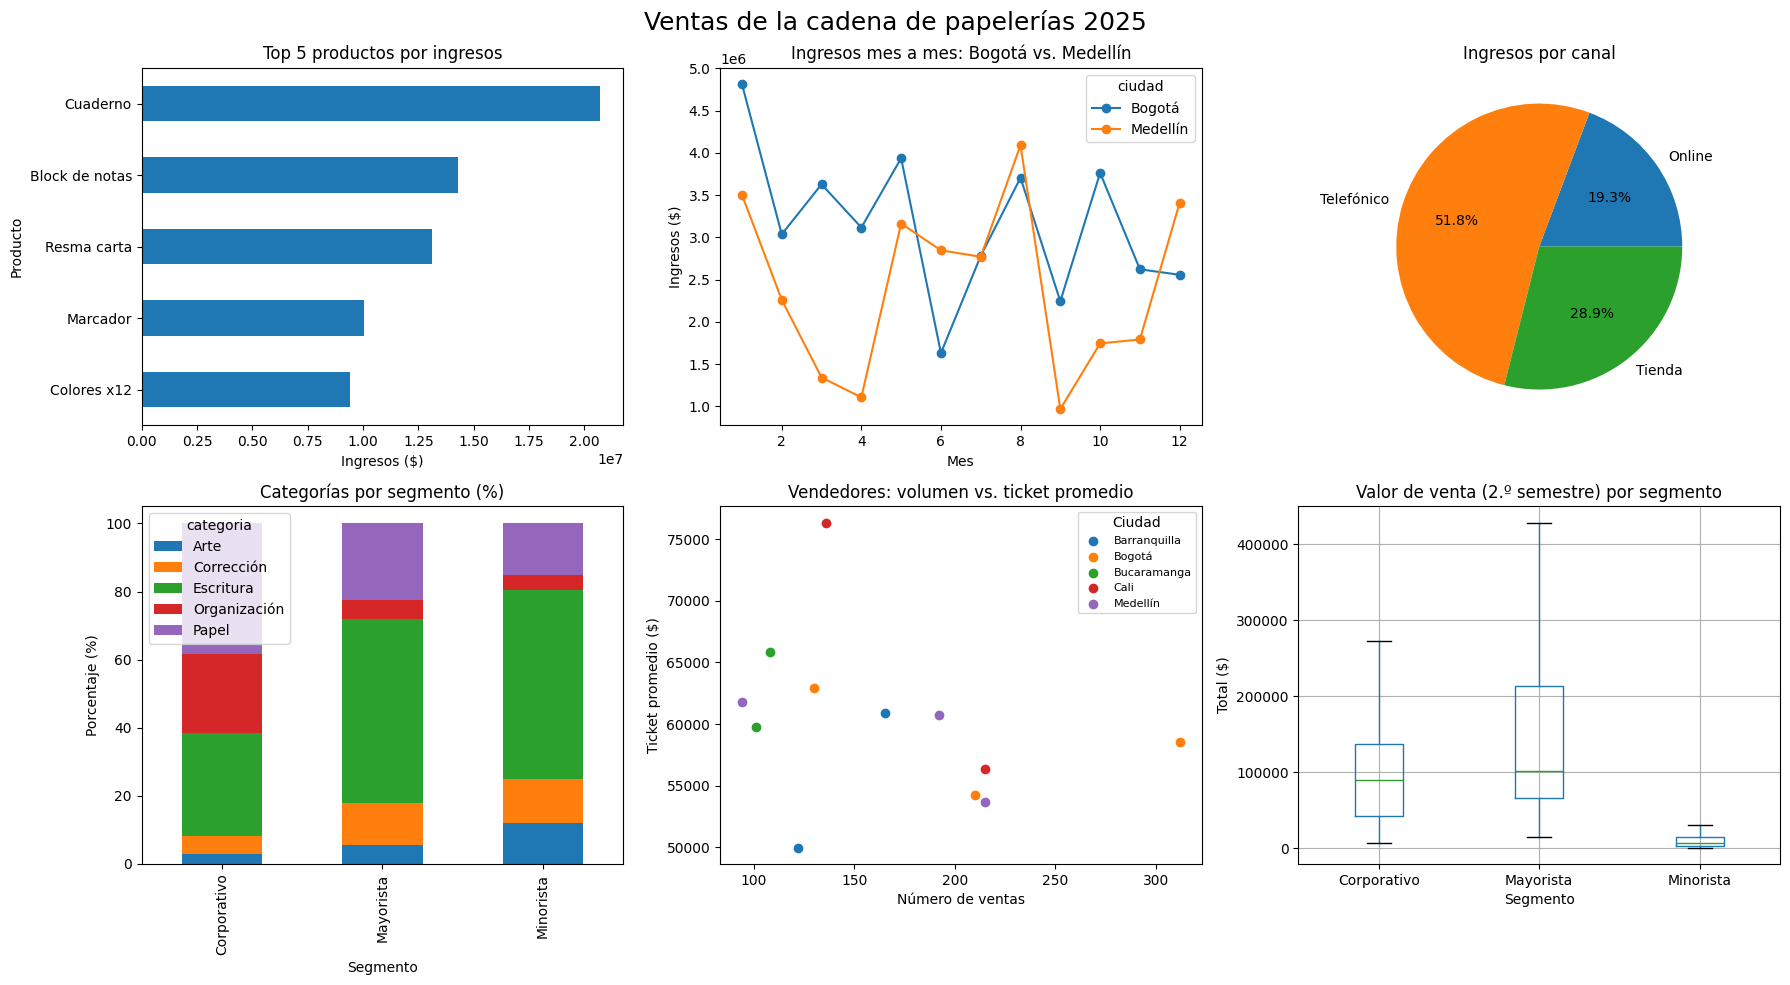

<Figure size 640x480 with 0 Axes>

In [ ]:
%run figura_base.py